In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


In [2]:
output_dir = Path(".")
np.random.seed(2727)
n = 300
ns = 20
h = n // ns
x = np.column_stack([np.random.randn(n), np.random.randn(n), np.random.randn(n)])
e = np.random.randn(n)
b1 = np.array([1, 1, 1])
b2 = np.array([1, -1, -1])
y = x @ b1 + (x @ b1) ** 3 + 4 * (x @ b2) ** 2 + e


In [3]:
x_mean = np.mean(x, axis=0)
slices = np.array_split(np.argsort(y), h)
m = np.zeros((x.shape[1], x.shape[1]))
for indices in slices:
    mean_difference = np.mean(x[indices], axis=0) - x_mean
    m += len(indices) * np.outer(mean_difference, mean_difference)
m /= n

cov = np.cov(x, rowvar=False)
cov_values, cov_vectors = np.linalg.eigh(cov)
cov_inverse_sqrt = cov_vectors @ np.diag(cov_values ** -0.5) @ cov_vectors.T
sir_matrix = cov_inverse_sqrt @ m @ cov_inverse_sqrt
g, directions = np.linalg.eigh(sir_matrix)
order = np.argsort(g)[::-1]
g = g[order]
f = cov_inverse_sqrt @ directions[:, order]
f /= np.linalg.norm(f, axis=0)

g = g / np.sum(g)
psi = np.cumsum(g)
p11 = np.column_stack([x @ f[:, 0], y])
p21 = np.column_stack([x @ f[:, 1], y])
p12 = np.column_stack([x @ f[:, 0], x @ f[:, 1], y])
m1 = np.column_stack([x @ b1, y])
m2 = np.column_stack([x @ b2, y])


findfont: Failed to find font weight heavy for DejaVu Sans, now using 700.


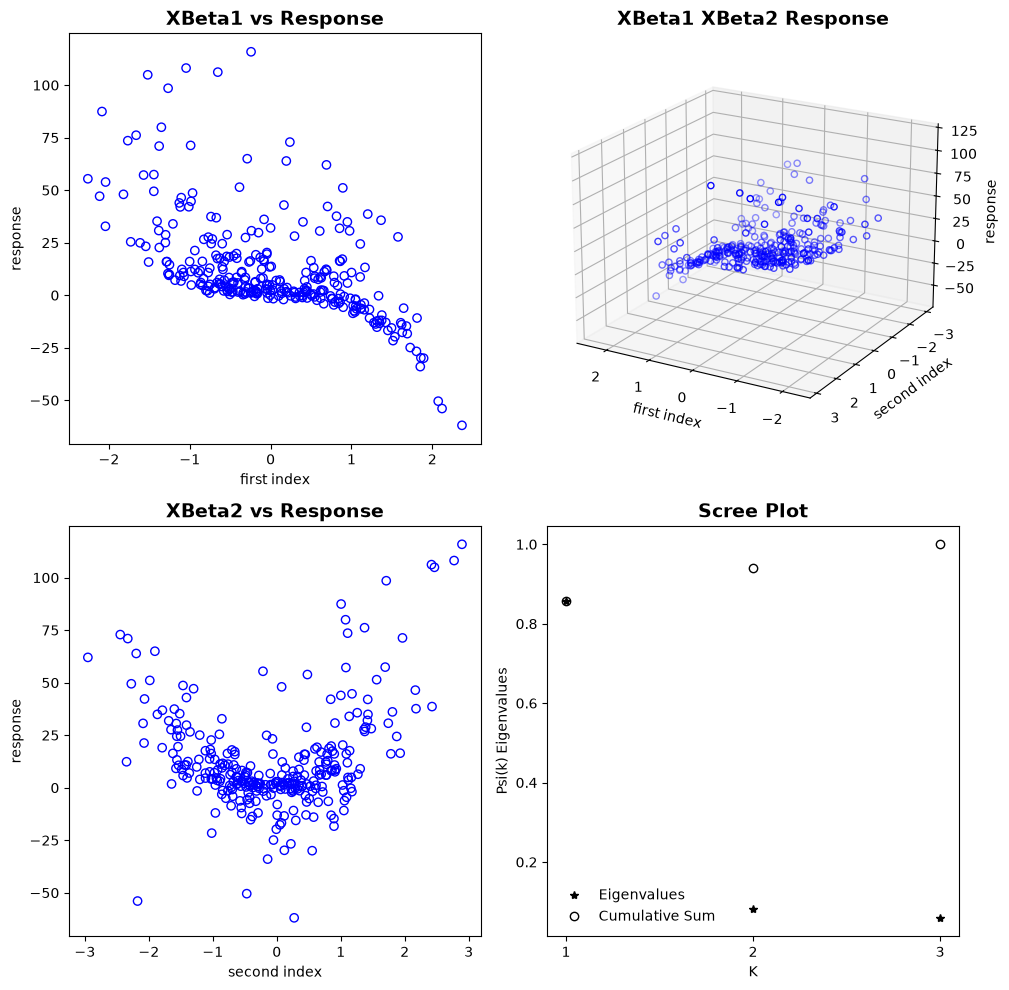

In [4]:
fig = plt.figure(figsize=(10, 10))

ax1 = fig.add_subplot(221)
ax1.scatter(p11[:, 0], p11[:, 1], edgecolors="b", facecolors="none")
ax1.set_xlabel("first index")
ax1.set_ylabel("response")
ax1.set_title("XBeta1 vs Response", fontweight="heavy", fontsize=14)

ax2 = fig.add_subplot(223)
ax2.scatter(p21[:, 0], p21[:, 1], edgecolors="b", facecolors="none")
ax2.set_xlabel("second index")
ax2.set_ylabel("response")
ax2.set_title("XBeta2 vs Response", fontweight="heavy", fontsize=14)

ax3 = fig.add_subplot(222, projection="3d")
ax3.scatter(p12[:, 0], p12[:, 1], p12[:, 2], edgecolors="b", facecolors="none")
ax3.set_xlabel("first index")
ax3.set_ylabel("second index")
ax3.set_zlabel("response")
ax3.set_title("XBeta1 XBeta2 Response", fontweight="heavy", fontsize=14)
ax3.view_init(elev=20, azim=120)

ax4 = fig.add_subplot(224)
i = np.arange(1, len(g) + 1)
ax4.plot(i, g, "*", c="k", label="Eigenvalues")
ax4.plot(i, psi, "o", c="k", markerfacecolor="none", label="Cumulative Sum")
ax4.set_xticks(i)
ax4.set_xlabel("K")
ax4.set_ylabel("Psi(k) Eigenvalues")
ax4.set_title("Scree Plot", fontweight="heavy", fontsize=14)
ax4.legend(frameon=False)

plt.tight_layout()
plt.savefig(output_dir / "20260915 MVAsirdata.png", transparent=True, dpi=300)
plt.show()


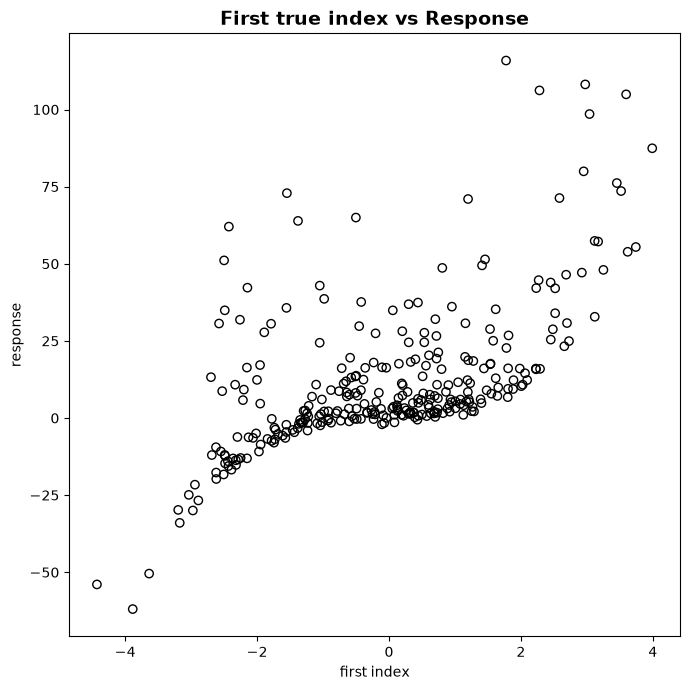

In [5]:
plt.figure(figsize=(7, 7))
plt.scatter(m1[:, 0], m1[:, 1], edgecolors="k", facecolors="none")
plt.xlabel("first index")
plt.ylabel("response")
plt.title("First true index vs Response", fontweight="heavy", fontsize=14)
plt.tight_layout()
plt.savefig(output_dir / "20260915 MVAsirdata_true1.png", transparent=True, dpi=300)
plt.show()


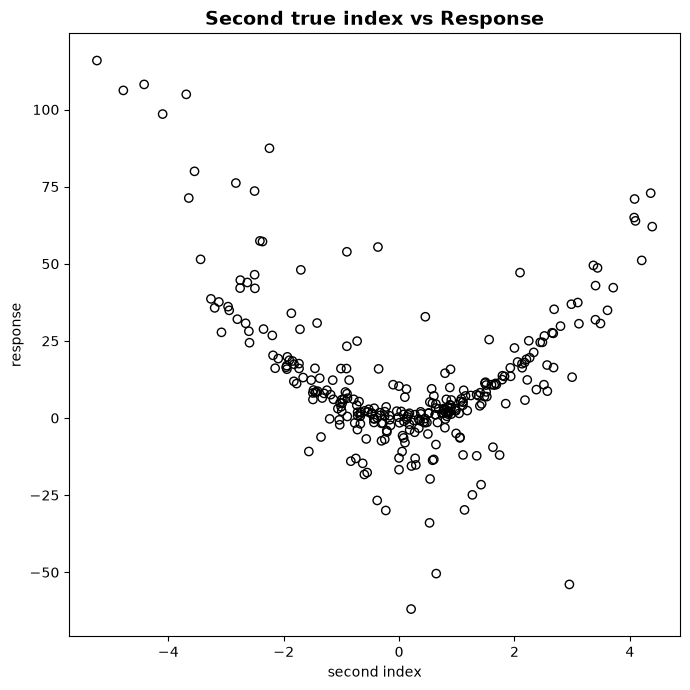

In [6]:
plt.figure(figsize=(7, 7))
plt.scatter(m2[:, 0], m2[:, 1], edgecolors="k", facecolors="none")
plt.xlabel("second index")
plt.ylabel("response")
plt.title("Second true index vs Response", fontweight="heavy", fontsize=14)
plt.tight_layout()
plt.savefig(output_dir / "20260915 MVAsirdata_true2.png", transparent=True, dpi=300)
plt.show()
